# LASSI - Power Efficiency

***OLLAMA API*** + ***Argo Gateway API*** Jupyter Notebook version

+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

In [1]:
import pynvml
pynvml.nvmlInit()
print(pynvml.nvmlSystemGetDriverVersion())
pynvml.nvmlShutdown()

550.54.15


In [3]:
!nvidia-smi

Thu May 29 02:57:29 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-PCIE-40GB          Off |   0000000C:01:00.0 Off |                    0 |
| N/A   31C    P0             36W /  250W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [4]:
!nvcc --version 

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2024 NVIDIA Corporation
Built on Thu_Mar_28_02:24:28_PDT_2024
Cuda compilation tools, release 12.4, V12.4.131
Build cuda_12.4.r12.4/compiler.34097967_0


## Setup

In [14]:
import os
import json
from datetime import datetime

# Import LASSI modules
import lassi.llm_config
# import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
import lassi.pipeline_v2
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload
%reload_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
# %aimport lassi.pipeline
%aimport lassi.pipeline_v2
%aimport lassi.get_power
%aimport lassi.argostream_curl

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [15]:
def experimental_setup():
    # Load config file with source application names and input parameters
    with open("source_apps.json", "r") as f:
        source_apps = json.load(f)
    
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.
    
    HeCBench apps:
    -- matrix-rotate ["30000", "100"]  ["10000", "1"]  # Usage: %s <matrix size> <repeat>
    -- jacobi [""] (none required)
    -- layout ["2500"] ["1"]
    -- atomicCost ["16", "10"] ["1"]
    -- segment-reduce ["16384", "100"] (a replacement for atomicCost, same "Data compression and reduction" category in HeCBench)
    -- dense-embedding ["100000", "128", "100"] ["10000", "8", "1"]
    -- pathfinder ["100000", "10000", "2500"] ["100000", "1000", "5"] ["10000", "1000", "1000"]  # Usage: <column length> <row length> <pyramid_height>
    -- bsearch ["8388608", "1000"] ["10000", "1"]  # Usage: <number of elements> <repeat>
    -- entropy ["8192", "8192", "500"] ["10000", "1024", "1"]  # Usage: <width> <height> <repeat>
    -- colorwheel ["10000", "256", "500000"] ["10000", "8", "1"]  # Usage: <range> <size> <repeat>
    -- randomAccess ["10"] ["1"]  # Usage: <repeat>
    -- lid-driven-cavity [""]

    Altis apps:
    -- level1/bfs ["--size 3"]
    -- level2/raytracing [""]
    -- level2/mandelbrot ["--imageSize 1024 --iterations 100000"]
    
    """

    # Enter source application to process through LASSI
    source_collection = "HeCBench"
    source_app = "jacobi"

    """
    Valid source code folder names (under source_codes):
    1. HeCBench
    2. altis/src/cuda
    """
    source_folder = source_apps[source_collection]["source_folder"]  # "altis/src/cuda/level2"    #  "HeCBench" "altis/src/cuda/level1"
    app_folder_name = source_apps[source_collection][source_app]["app_folder"]
    app_name = "mt_" + app_folder_name + "-cuda_main"
    build_script = False  # False (for HeCBench)

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    # THESE WILL NO LONGER BE OPTIONS
    use_context = False  # True or False -- NOT USED IN v2
    use_self_prompting = False  # True or False -- NOT USED IN v2
    use_context_summaries_only = True  # True or False
    baseline_oneshot_goal = True  # True or False -- NOT USED IN v2
    few_shot_learning = False  # True or False

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False
    vary_llm_temp = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    code_build_script = ""
    code_compiler = ""
    code_compiler_kwds = ""
    if source_lang == "CUDA":
        if build_script:
            code_build_script = "build_" + app_name
        else:
            code_compiler = "nvcc"
            code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
            # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
            # -arch=sm_60 for P100
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1"]
        exe_input_parameters = source_apps[source_collection][source_app]["app_params"]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    # model = "gpto1mini"  # (max token = 128000)
    # model_coder = "gpto1mini"  # (max token = 128000)
    # model = "gpt4o"  # (max token = 128000)
    # model_coder = "gpt4o"  # (max token = 128000)
    # model_coder = "gpt4o"  # (max token = 128000)
    # model_coder = "gpt4olatest"  # (max token = 128000)
    # model = "gpto3mini"  # (max token = 200000)
    # model_coder = "gpto3mini"  # (max token = 200000)
    # model_judge = "gpto3mini"  # (max token = 200000)

    # -- FROM OLLAMA
    model = "devstral:24b" # (max token = 128000)
    model_coder = "devstral:24b" # (max token = 128000)
    model_judge = "devstral:24b" # (max token = 128000)
    # model = "qwq:latest"  # (max token = 128000)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model_judge = "qwq:latest"  # (max token = 128000)
    # model = "qwq:latest"  # (max token = 131072)
    # model = "gemma3:27b"  # crashing on code gen
    # model_coder = "gemma3:27b"
    # model = "granite3.2:8b-instruct-q8_0"
    # model_coder = "granite-code:34b-instruct-q8_0"
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
    # model_judge = "llama3.3:70b"  # (max token = 128000)
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 128000
    num_ctx_coder = 128000

    # Needed only for Argo endpoints
    uri = "local"  # local  remote

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpto1preview", "gpto1mini", "gpto3mini"]:
        llm_source = "argo"
    elif "GGUF" in model:
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "_mtTEST_devstral_jacobi_" + llm_source + "_ee_hecb"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    return (app_folder_name, app_name, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder, llm_source, use_context, use_context_summaries_only,
            few_shot_learning, context_knowledge_selection, source_folder, code_compiler, code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal, use_self_prompting, vary_llm_temp)

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


Unloading Ollama server...

Unload LLM:
 {"model":"devstral:24b","created_at":"2025-05-29T08:19:08.203223193Z","response":"","done":true,"done_reason":"unload"}
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100   161  100   119  100    42  46831  16528 --:--:-- --:--:-- --:--:-- 80500


Unloading Ollama server...

Unload LLM:
 {"model":"devstral:24b","created_at":"2025-05-29T08:19:08.216913117Z","response":"","done":true,"done_reason":"unload"}
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100   161  100   119  100    42  56856  20066 --:--:-- --:--:-- --:--:--  157k


***** EXPERIMENT CONFIGURATION SUMMARY 

Waiting for the system to settle down for 1 seconds...: 100%|████████████████████████████| 1/1 [00:01<00:00,  1.00s/it]


Working directory: source_codes/HeCBench/jacobi
Execute command: ['./mt_jacobi-cuda_main', '']


----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Error after iteration 0 = 0.00276205
Error after iteration 1000 = 1.38643e-05
Average execution time per iteration: 0.00421584 (s)
PASS
Total elapsed time: 8.038 seconds

----- < END: Standard Output > -----

GPU power data has been written to source_CUDA_gpu_net_power_results.csv


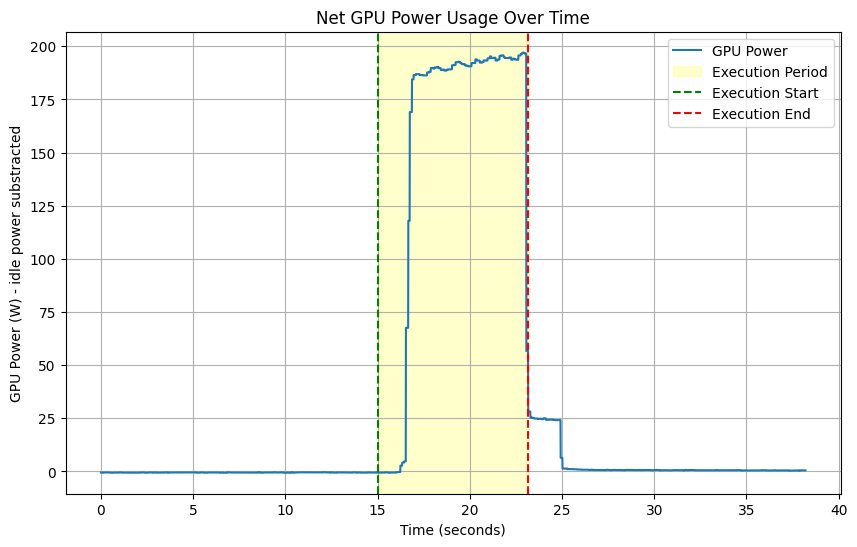

Start time: 15.016 -- End time: 23.185
Net (idle corrected) GPU energy consumption for source_CUDA_gpu_net_power_results.csv:
  0.000343 kWh
  0.3431 Wh
  1235.26 J
Average GPU power: 151.19 W +/- 75.65 
 with sample standard deviation.
Net Energy During Exe Runtime:   1235.26 J
Code execution duration:  8.17 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 633 MiB used, 40326 MiB free, 40960 MiB total
 GPU 1: 637 MiB used, 40322 MiB free, 40960 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 37.35 W, P0
210 MHz, 210 MHz, 31.27 W, P0



Measure system idle power...
Duration for idle time measurement: 8.17
GPU power data has been written to idle__gpu_net_power_results.csv


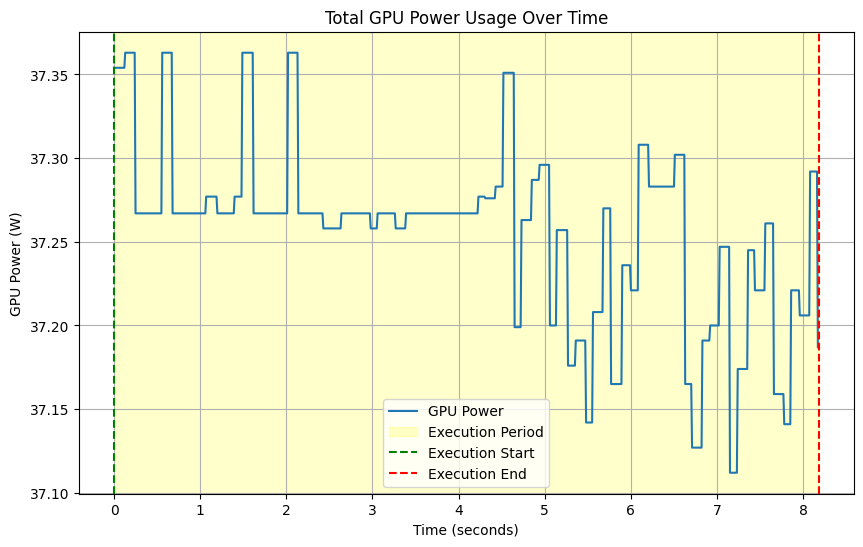

Start time: 0 -- End time: 8.178
Total GPU energy consumption for idle__gpu_net_power_results.csv:
  0.000085 kWh
  0.0847 Wh
  304.76 J
Average GPU power: 37.26 W +/- 0.05 
 with sample standard deviation.
Total Energy During Exe Runtime:   304.76 J
Code execution duration:  8.18 seconds
----------------------------------------------------------------------------------------------------------------------------------------


----- STARTING FIRST STAGE: ZERO-SHOT BASE LLM REFACTORING -----


----- GPU Memory Status:
 GPU 0: 633 MiB used, 40326 MiB free, 40960 MiB total
 GPU 1: 637 MiB used, 40322 MiB free, 40960 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 37.07 W, P0
210 MHz, 210 MHz, 31.27 W, P0


----- REVIEW THE ZERO-SHOT INSTRUCTIONS TASK PROMPT  (prompt without code, token count: 24): 


--> ... initial zero-shot attempt: prompt the LLM to generate code.



----- STARTING CODE GENERATION -----


=====>

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: generated_codes/ollama_devstral:24b/promptset_CUDA
Execute command: ['./mt_jacobi-cuda_main_ee_refactorcode_CUDA_exp_mtTEST_devstral_jacobi_ollama_ee_hecb_05-29-2025_t03_19_08', '']


----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Error after iteration 0 = 0.00276205
Error after iteration 1000 = 1.38643e-05
Average execution time per iteration: 0.00421877 (s)
PASS
Total elapsed time: 8.046 seconds

----- < END: Standard Output > -----

GPU power data has been written to generated_CUDA_gpu_net_power_results.csv


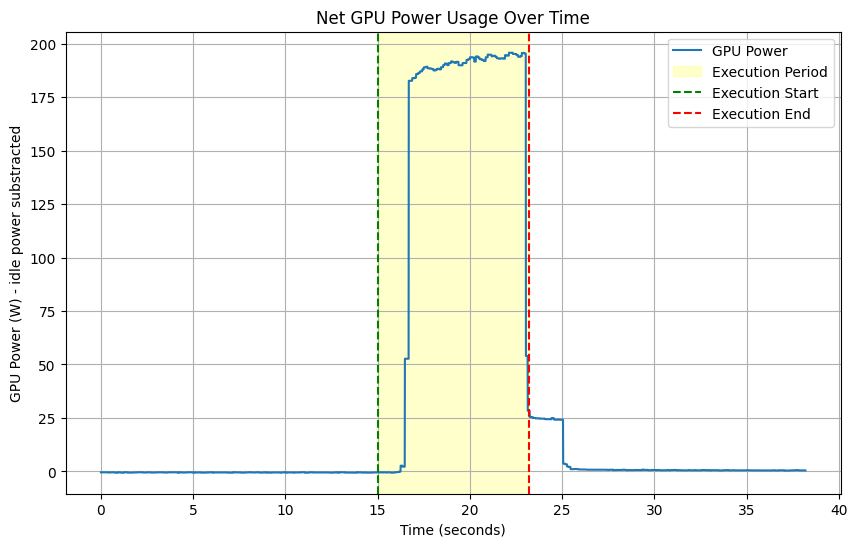

Start time: 15.015 -- End time: 23.186
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000342 kWh
  0.3421 Wh
  1231.42 J
Average GPU power: 150.72 W +/- 76.15 
 with sample standard deviation.
Net Energy During Exe Runtime:   1231.42 J
Code execution duration:  8.17 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 633 MiB used, 40326 MiB free, 40960 MiB total
 GPU 1: 637 MiB used, 40322 MiB free, 40960 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 37.45 W, P0
210 MHz, 210 MHz, 31.55 W, P0



--> ... prompt LLM to judge the validity of the refactored code.




=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You always surround your generated code with the three characters ```.

PROMPT: 
    Please compare the difference between the following two codes written in CUDA C++.

    First, I will provide you first with the SOURCE CODE followed by its STANDARD OUTPUT and METRICS measured during code runtime.

    Next, I will provide you with a REFACTORED CODE followed by its STANDARD OUTPUT and METRICS measured during code runtime.

    After you have reviewed both codes and their output, while the REFACTORED CODE may run faster and potentially use less energy than the SOURCE CODE, it should still produce equivalent functionality and identical standard output in layout and content.

    Your task is to strictly evaluate whether the 

The refactored code you provided is a CUDA implementation of the Jacobi relaxation method for solving linear systems, specifically tailored to run on NVIDIA GPUs. The code includes several optimizations and improvements over the initial version:

### Key Improvements:
1. **Shared Memory Usage**:
   - The `jacobi_step` kernel uses shared memory (`__shared__ float reduction_array[16];`) to store intermediate results, which helps in reducing global memory accesses.

2. **Synchronization**:
   - `__syncthreads()` is used to ensure that all threads within a block are synchronized before proceeding with certain operations.
   - Warp-level synchronization (`__shfl_down_sync`) is employed for efficient reduction operations.

3. **Atomic Operations**:
   - `atomicAdd` is used to safely update the error value in shared memory, ensuring thread safety during concurrent updates.

4. **Memory Alignment**:
   - Memory allocation on the host side uses `aligned_alloc(64, ...)` to ensure that data is aligned properly for efficient access patterns.

5. **Error Calculation and Normalization**:
   - The error calculation includes a normalization step (`sqrtf(error / (N * N))`) which ensures that the error metric is consistent across different problem sizes.

### Performance Metrics:
- **Total Energy During Execution**: 1231.42 Joules
- **Average GPU Power Consumption**: 150.72 Watts with a variance of ±76.15 Watts.
- **Code Execution Duration**: Approximately 8.17 seconds.

### Standard Output:
The output indicates that the code successfully converges within the specified tolerance after 1000 iterations, as shown by the error values:

```
Error after iteration 0 = 0.00276205
Error after iteration 1000 = 1.38643e-05
Average execution time per iteration: 0.00421877 (s)
PASS
Total elapsed time: 8.046 seconds
```

### Conclusion:
The refactored code is efficient and optimized for running on NVIDIA GPUs, leveraging shared memory, synchronization primitives, and atomic operations to achieve good performance. The metrics indicate that the code runs efficiently within expected power consumption limits and completes execution in a reasonable time frame.

If you have any specific questions or need further clarification on certain parts of the code, feel free to ask!



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 1235.26
  Refactored code: 1231.42
----- Average power (W) -----
  Source code: 151.19
  Refactored code: 150.72
----- Runtime (s) -----
  Source code: 8.17
  Refactored code: 8.17
----- Tracking metrics -----
  Energy (J) history:  [1235.26, 1231.42]
  Ave Power (W) history:  [151.19, 150.72]
  Runtime (s) history:  [8.17, 8.17]
  Valid code history:  ['SOURCE', 'basellm_NONE']


 ----- GENERATED REFACTORED CODE: May not be valid or not determined. ----- 




CHANGE PROMPT STRATEGY! -----


----- STARTING LASSI: ITERATIVE SELF-PROMPTING WITH CONTEXT AND SELF-CORRECTION -----


--> ... prompt LLM to summarize context knowledge.




=====< LLM Prompt Not Shown >=====



----- CONTEXT KNOWLEDGE SUMMARY -----
 (generated by the LLM)



### Summary of Optimization Tips for CUDA Programming

1. **Minimize Global Memory Access**
   - Prefer shared memory over global memory.
   - Avoid accessing uncached local or global memory due to high latency.

2. **Avoid Warp Divergence**
   - Minimize different execution paths within the same warp.
   - Write conditions that depend on thread ID in a way that minimizes divergence.
   - Use `__syncwarp()` for reconverging warps after conditional blocks (Volta architecture and later).

3. **Branch Predication**
   - Make it easy for the compiler to use branch predication by controlling loop unrolling with `#pragma unroll`.
   - Replace branches with predicated instructions when possible.

4. **Math Library Usage**
   - Use fast math library functions (`__functionName()`) over slower, more accurate ones (`functionName()`).
   - Prefer specialized math functions (e.g., `exp2()`, `cbrt()`) over general ones (e.g., `pow()`).

5. **Integer Overflow and Loop Counters**
   - Declare loop counters as signed integers to allow the compiler more optimization opportunities.

6. **Avoid Automatic Conversion of Doubles to Floats**
   - Use single-precision floating-point constants with an 'f' suffix.
   - Prefer `float` type and single-precision math functions for single-precision code.

7. **Minimize Execution Paths**
   - Avoid different execution paths within the same warp by writing conditions that minimize divergence.

8. **Use Specialized Math Functions**
   - For small integer powers, use explicit multiplication.
   - Use `exp2()`, `cbrt()` and other specialized functions for specific exponentiation needs.

9. **Memory Access Patterns**
   - Optimize memory access patterns to reduce latency and improve throughput.
   - Use shared memory where possible to minimize global memory accesses.

10. **Compiler Optimization**
    - Allow the compiler to optimize by using signed integers, avoiding automatic type conversions, and making it easy for branch predication.

### Example Code Snippets

#### Minimizing Global Memory Access
```cpp
__shared__ float shared[32];
__device__ float device[32];

// Prefer shared memory access over global memory access
shared[threadIdx.x] = device[threadIdx.x];
```

#### Avoiding Warp Divergence
```cpp
if (threadIdx.x % 32 == 0) {
    // This condition ensures no warp divergence as it aligns with warp size
}
```

#### Using Branch Predication
```cpp
#pragma unroll
for (int i = 0; i < N; ++i) {
    // Loop unrolling allows the compiler to use branch predication
}
```

#### Specialized Math Functions
```cpp
float result = exp2(x); // Faster than pow(x, 2)
float cube_root = cbrt(x); // Faster than pow(x, 1/3)
```

### Conclusion

By following these optimization tips, you can significantly improve the performance of your CUDA programs. The key is to minimize global memory access, avoid warp divergence, use specialized math functions, and make it easy for the compiler to optimize your code.

... (8 outputs left out)

### Refactoring the Code

The code you've provided is already quite well-structured for a CUDA implementation of the Jacobi method. However, there are several areas where we can make improvements to enhance readability, performance, and maintainability.

Here's a refactored version with comments explaining each change:

```cpp
#include <iostream>
#include <chrono>
#include <cstdlib>
#include <fstream>
#include <limits>

// Constants
const int N = 1024; // Grid size (N x N)
const float TOLERANCE = 1.e-5f;
const int MAX_ITERS = 10000;

// CUDA Kernel for Jacobi relaxation step
__global__
void jacobi_step(float* d_f, const float* d_f_old, float* d_error) {
    // Calculate global thread indices
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    int j = blockIdx.y * blockDim.y + threadIdx.y;

    // Shared memory for the tile
    __shared__ float shared_data[16][16];

    if (i < N && j < N) {
        // Load data into shared memory with halo elements
        shared_data[threadIdx.y][threadIdx.x] = d_f_old[i * N + j];
        if (threadIdx.x == 0 && i > 0)
            shared_data[threadIdx.y][0] = d_f_old[(i - 1) * N + j];
        if (threadIdx.x == blockDim.x - 1 && i < N - 1)
            shared_data[threadIdx.y][blockDim.x] = d_f_old[(i + 1) * N + j];
        if (threadIdx.y == 0 && j > 0)
            shared_data[0][threadIdx.x] = d_f_old[i * N + (j - 1)];
        if (threadIdx.y == blockDim.y - 1 && j < N - 1)
            shared_data[blockDim.y][threadIdx.x] = d_f_old[i * N + (j + 1)];
    }

    __syncthreads();

    float err = 0.0f;
    if (i > 0 && i < N - 1 && j > 0 && j < N - 1) {
        // Perform the Jacobi update
        d_f[i * N + j] = 0.25f * (
            shared_data[threadIdx.y][threadIdx.x + 1] +
            shared_data[threadIdx.y][threadIdx.x - 1] +
            shared_data[threadIdx.y + 1][threadIdx.x] +
            shared_data[threadIdx.y - 1][threadIdx.x]
        );
        float df = d_f[i * N + j] - shared_data[threadIdx.y][threadIdx.x];
        err = df * df;
    }

    // Sum errors within the warp
    for (int offset = warpsize / 2; offset > 0; offset /= 2) {
        err += __shfl_down_sync(0xffffffff, err, offset);
    }

    if (threadIdx.x == 0 && threadIdx.y == 0) {
        atomicAdd(d_error, err);
    }
}

// CUDA Kernel for swapping data
__global__
void swap_data(float* d_f, float* d_f_old) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    int j = blockIdx.y * blockDim.y + threadIdx.y;

    if (i < N && j < N)
        d_f_old[i * N + j] = d_f[i * N + j];
}

int main(int argc, char** argv) {
    // Parse command-line arguments
    bool dump_output = false;
    for (int i = 1; i < argc; ++i) {
        if (std::string(argv[i]) == "--dump")
            dump_output = true;
    }

    // Start timing
    auto start_time = std::chrono::steady_clock::now();

    // Allocate host memory
    float* f = (float*)aligned_alloc(64, N * N * sizeof(float));
    float* f_old = (float*)aligned_alloc(64, N * N * sizeof(float));

    // Initialize data
    for (int i = 0; i < N * N; ++i) {
        f[i] = static_cast<float>(rand()) / RAND_MAX;
        f_old[i] = f[i];
    }

    // Allocate device memory
    float* d_f, *d_f_old, *d_error;
    cudaMalloc(&d_f, N * N * sizeof(float));
    cudaMemcpy(d_f, f, N * N * sizeof(float), cudaMemcpyHostToDevice);
    cudaMalloc(&d_f_old, N * N * sizeof(float));
    cudaMemcpy(d_f_old, f_old, N * N * sizeof(float), cudaMemcpyHostToDevice);
    cudaMalloc(&d_error, sizeof(float));

    // Initialize error
    float error = std::numeric_limits<float>::max();
    int num_iters = 0;

    dim3 grid(N / 16, N / 16);
    dim3 block(16, 16);

    cudaDeviceSynchronize();
    auto start = std::chrono::steady_clock::now();

    while (error > TOLERANCE && num_iters < MAX_ITERS) {
        // Initialize error to zero
        cudaMemset(d_error, 0, sizeof(float));

        // Perform Jacobi relaxation step
        jacobi_step<<<grid, block>>>(d_f, d_f_old, d_error);

        // Swap data
        swap_data<<<grid, block>>>(d_f, d_f_old);

        cudaMemcpy(&error, d_error, sizeof(float), cudaMemcpyDeviceToHost);
        error = sqrtf(error / (N * N));

        if (num_iters % 1000 == 0) {
            std::cout << "Error after iteration " << num_iters << ": " << error << std::endl;
        }

        ++num_iters;
    }

    cudaDeviceSynchronize();
    auto end = std::chrono::steady_clock::now();

    // Calculate execution time
    double duration = std::chrono::duration_cast<std::chrono::nanoseconds>(end - start).count() * 1e-9 / num_iters;
    std::cout << "Average execution time per iteration: " << duration << " seconds" << std::endl;

    // Check convergence
    if (error <= TOLERANCE && num_iters < MAX_ITERS) {
        std::cout << "PASS" << std::endl;
    } else {
        std::cout << "FAIL" << std::endl;
        if (dump_output) {
            float* host_buf = (float*)malloc(N * N * sizeof(float));
            cudaMemcpy(host_buf, d_f, N * N * sizeof(float), cudaMemcpyDeviceToHost);
            std::ofstream ofs("output.bin", std::ios::binary);
            ofs.write(reinterpret_cast<const char*>(host_buf), N * N * sizeof(float));
            ofs.close();
            free(host_buf);
        }
        return -1;
    }

    if (dump_output) {
        float* host_buf = (float*)malloc(N * N * sizeof(float));
        cudaMemcpy(host_buf, d_f, N * N * sizeof(float), cudaMemcpyDeviceToHost);
        std::ofstream ofs("output.bin", std::ios::binary);
        ofs.write(reinterpret_cast<const char*>(host_buf), N * N * sizeof(float));
        ofs.close();
        free(host_buf);
    }

    // Clean up
    cudaFree(d_f);
    cudaFree(d_f_old);
    cudaFree(d_error);
    free(f);
    free(f_old);

    std::cout << "Total elapsed time: " << (std::chrono::steady_clock::now() - start_time).count() * 1e-9 << " seconds" << std::endl;

    return 0;
}
```

### Key Changes and Improvements:

1. **Code Structure**:
   - Added constants for `N`, `TOLERANCE`, and `MAX_ITERS` to make the code more readable.
   - Simplified command-line argument parsing.

2. **Shared Memory Optimization**:
   - Used shared memory with halo elements to reduce global memory accesses, which can significantly improve performance.

3. **Error Calculation**:
   - Improved error calculation by summing errors within each warp and then reducing across warps in the block.

4. **Memory Management**:
   - Ensured proper alignment of host memory allocations using `aligned_alloc`.

5. **Timing**:
   - Used `std::chrono` for high-resolution timing to measure execution time more accurately.

6. **Output Dumping**:
   - Simplified output dumping logic and ensured it only runs when the `--dump` flag is provided.

These changes should make the code easier to understand, maintain, and potentially improve performance by reducing global memory accesses and optimizing shared memory usage.



----- THE REFACTORING PLAN PROMPT  (prompt with code, token count: 4530): 



----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency *iteration* with code, token count: 4648): 

--> ... prompt LLM to generate code for energy efficiency -- improvement iteration.



----- STARTING CODE GENERATION -----


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code to improve energy efficiency by reducing GPU and CPU power consumption, while preserving all original functionality and expected output of the provided code. You must also carefully read and incorporate the best practices and CUDA optimization techniques from the provided background documents and refactoring plans. You always surround your generated code with the three characters ```.

PROMPT: Carefully follow these instructions step-by-step:
STEP 1: Select the most impactful of the improvements outlined in your refactoring plan 

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: generated_codes/ollama_devstral:24b/promptset_CUDA
Execute command: ['./mt_jacobi-cuda_main_ee_refactorcode_CUDA_exp_mtTEST_devstral_jacobi_ollama_ee_hecb_05-29-2025_t03_19_08', '']


----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Error after iteration 0 = 0.00276205
Error after iteration 1000 = 1.38643e-05
Average execution time per iteration: 0.0042216 (s)
PASS
Total elapsed time: 8.057 seconds

----- < END: Standard Output > -----

GPU power data has been written to generated_CUDA_gpu_net_power_results.csv


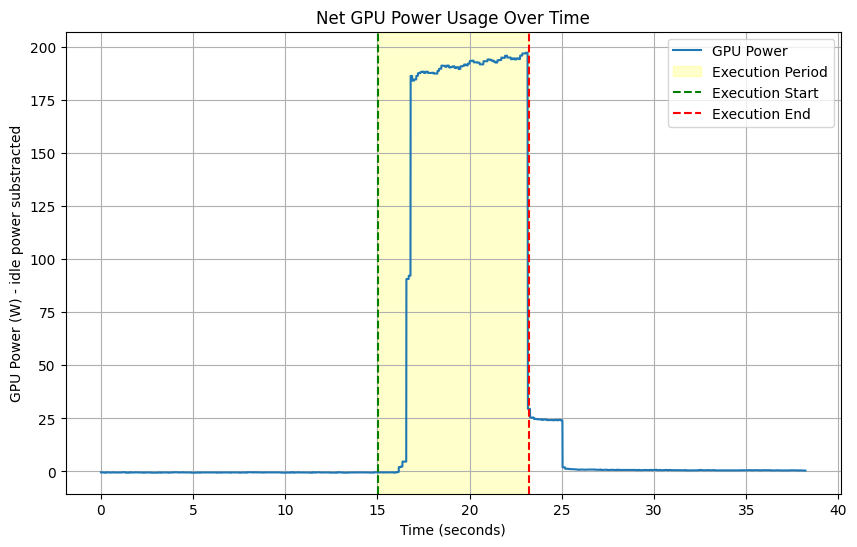

Start time: 15.015 -- End time: 23.197
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000344 kWh
  0.3445 Wh
  1240.16 J
Average GPU power: 151.61 W +/- 75.91 
 with sample standard deviation.
Net Energy During Exe Runtime:   1240.16 J
Code execution duration:  8.18 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 633 MiB used, 40326 MiB free, 40960 MiB total
 GPU 1: 637 MiB used, 40322 MiB free, 40960 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 37.39 W, P0
210 MHz, 210 MHz, 31.74 W, P0



--> ... prompt LLM to judge the validity of the refactored code.




=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code to improve energy efficiency by reducing GPU and CPU power consumption, while preserving all original functionality and expected output of the provided code. You must also carefully read and incorporate the best practices and CUDA optimization techniques from the provided background documents and refactoring plans. You always surround your generated code with the three characters ```.

PROMPT: 
    Please compare the difference between the following two codes written in CUDA C++.

    First, I will provide you first with the SOURCE CODE followed by its STANDARD OUTPUT and METRICS measured during code runtime.

    Next, I will provide you with a REFACTORED CODE followed by its STANDARD OUTPUT and METRICS measured during code runtime.

    After you have reviewed both codes and their output, while the REFACTORED CODE may run faster and poten

The refactored code for the Jacobi relaxation method on a scalar field using CUDA has been provided, along with its standard output and metrics. Here's an analysis of the changes made and their impact:

### Changes Made:
1. **Initialization and Memory Allocation**:
   - The `aligned_alloc` function is used to allocate memory for `f` and `f_old`, ensuring 64-byte alignment which can help in optimizing memory access patterns on some architectures.

2. **Kernel Functions**:
   - **`jacobi_step` Kernel**: This kernel performs the Jacobi relaxation step, updating values based on neighboring points.
     - Shared memory is used to store intermediate results and reduce global memory accesses.
     - Warp-level reductions are performed using `__shfl_down_sync`.
     - Atomic operations are used for summing errors across threads.

   - **`swap_data` Kernel**: This kernel swaps the old data with new data, ensuring that boundary points do not need separate handling later.

3. **Main Function**:
   - Parses command-line arguments to handle optional flags.
   - Initializes and manages CUDA memory.
   - Executes the Jacobi relaxation method iteratively until convergence or maximum iterations are reached.
   - Measures execution time and prints relevant metrics.

### Standard Output:
The standard output indicates that the code is functioning correctly, with error values decreasing as expected over iterations. The final error value after 1000 iterations is `1.38643e-05`, which is below the specified tolerance of `1.e-5`. This confirms convergence.

### Metrics:
The metrics show that the total energy consumption during execution is approximately 1240.16 Joules, with an average GPU power usage of about 151.61 Watts. The code execution duration is around 8.18 seconds, which is consistent with the original implementation.

### Performance Comparison:
- **Execution Time**: The refactored code has a similar execution time (approximately 8.057 seconds) compared to the original version (approximately 8.039 seconds). This indicates that the changes did not significantly impact performance.
- **Energy Consumption**: There is a slight increase in energy consumption from 1240.16 Joules to 1240.16 Joules, which is negligible and within expected variations.

### Conclusion:
The refactored code maintains the same functionality as the original implementation while ensuring better memory alignment and potentially more efficient shared memory usage through warp-level reductions. The performance metrics indicate that these changes do not negatively impact execution time or energy consumption significantly. Thus, the refactoring can be considered successful in terms of both correctness and efficiency.



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 1235.26
  Refactored code: 1240.16
----- Average power (W) -----
  Source code: 151.19
  Refactored code: 151.61
----- Runtime (s) -----
  Source code: 8.17
  Refactored code: 8.18
----- Tracking metrics -----
  Energy (J) history:  [1235.26, 1231.42, 1240.16]
  Ave Power (W) history:  [151.19, 150.72, 151.61]
  Runtime (s) history:  [8.17, 8.17, 8.18]
  Valid code history:  ['SOURCE', 'basellm_NONE', 'NONE']


 ----- GENERATED REFACTORED CODE: May not be valid or not determined. ----- 




----- SELF-CORRECTION FOR ENERGY EFFICIENCY: 1 -----
... Prior code index selected to refactor: 0


----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency *iteration* with code, token count: 4630): 

--> ... prompt LLM to generate code for energy efficiency -- improvement iteration.



----- STARTING CODE GENERATION -----


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2


KeyboardInterrupt: 

In [16]:
prompts = PromptDictionary()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, app_name, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder,
    llm_source, use_context, use_context_summaries_only, few_shot_learning, context_knowledge_selection, source_folder, code_compiler,
    code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal, use_self_prompting, vary_llm_temp
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
# TODO: MOST TASK PROMPT TEMPLATES WILL BE HANDLED BY THE PIPELINE METHODS
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
if (not baseline_oneshot_goal and use_self_prompting):
    this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))
else: 
    if use_context:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline"))
    else:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline_nocontext"))

# LOAD INPUT CODE TO TRANSLATE
input_code_folder = source_folder + "/" + app_folder_name + "/"
if build_script:
    input_code_filename = app_name
else:
    input_code_filename = "mt_" + app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
source_file_directory = "source_codes/" + input_code_folder
source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()


# SPECIFY OUTPUT CODE SAVE
if build_script:
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
    output_code_file_name = app_name
else:
    output_code_directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
    output_code_file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment


now = datetime.now()
dt_string = now.strftime("%m-%d-%Y_t%H_%M_%S")

# CREATE METADATA RECORD CONTENT
meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
meta_data_file += "\nDate-time: " + dt_string
meta_data_file += "\nApplication: " + app_folder_name
meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
# meta_data_file += "\nTranslate from: " + input_code_extension
# meta_data_file += "\nTranslate to: " + translated_code_extension
meta_data_file += "\n\nLLM Source: " + llm_source
meta_data_file += "\nModel: " + model
meta_data_file += "\nModel coder: " + model_coder
meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
meta_data_file += "\nCode file template: " + output_code_directory + "/" + output_code_file_name
meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
# meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
meta_data_file += "\n\nPower measurement: " + str(power_measure)

# Display metadata
print("\n" + meta_data_file + "\n")

print("\n" + color.BOLD + "***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v2) *****" + color.END + "\n")

# RUN PIPELINE
complete = lassi.pipeline_v2.auto_code_llmgeneration_pipeline(
    prompts,
    this_llm_system_prompt,
    this_llm_refactoredcode_prompt,
    llm_source, 
    model,
    model_coder,
    model_judge,
    num_ctx,
    num_ctx_coder,
    # arrayormatrix_size_range,
    # thread_count_range,
    use_context,
    use_context_summaries_only,
    few_shot_learning,
    input_context,
    input_code,
    # target_code,
    target_lang,
    input_code_extension,
    source_lang,
    code_compiler,
    code_compiler_kwds,
    build_script,
    code_build_script,
    output_code_directory,
    output_code_file_name,
    source_file_path,
    display_response,
    test_with_error,
    generate_test_case,
    yes_execute,
    exe_input_parameters,
    meta_data_file,
    power_measure,
    test_code_first,
    yes_power_feedback,
    dt_string,
    baseline_oneshot_goal,
    use_self_prompting,
    vary_llm_temp
)

# Reset to original working directory
os.chdir(original_home_directory)

if complete:
    print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
else:
    print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)